In [668]:
#Requirements: Wilson's correletion to estimate K-values
 #root finding technique (bisection method)
 #plot RR function with respect to beta_v
 #compositions of liquid and vapor phases

In [ ]:
#setup no. 2
import numpy as np
import matplotlib.pyplot as plt

#set variables and formats
Tc = np.array([0,0,0])
Pc = np.array([0,0,0])
z = np.array([0,0,0])
omega = np.array([0,0,0])
beta_v = 0 
rr = 0

def Wilson_K(T, P, Tc, Pc, omega):
    K = (Pc / P) * np.exp(5.373 * (1 + omega) * (1 - Tc / T))
    return 'K_1 = {}; '.format(K[0].round(2)) + 'K_2 = {}; ' .format(K[1].round(2)) + 'K_3 = {}'.format(K[2].round(2))

def RR_Eval(z, K, beta_v):
    rr = np.sum(((1 - K) * z) / (1 - (1 - K) * beta_v)).round(2)
    return float(rr)

def Rachford_Rice(z, K):
    tol = 1e-6
    max_iter = 100
    beta_v_min = 1 / (1 - np.max(K))
    beta_v_max = 1 / (1 - np.min(K))
    beta_v_l = beta_v_min
    beta_v_h = beta_v_max
    iteration = 1
    beta_v = (beta_v_min + beta_v_max) / 2

    beta_v = (beta_v_min + beta_v_max) / 2
    for iteration in range(max_iter):
        RR = np.sum(((1 - K) * z) / (1 - (1 - K) * beta_v))
        if abs(RR) < tol:
            break
        if RR > 0 + tol:
            beta_v_h = beta_v
        if RR < 0 - tol:
            beta_v_l = beta_v
        beta_v = (beta_v_l + beta_v_h) / 2
        iteration += 1
            
    x = z / (1 + (K - 1) * beta_v)
    y = K * x
    return "Beta_V,root = {}; Beta_V,min = {}; Beta_V,max = {}; X_V = {}; X_L = {}".format(
        beta_v.round(2), beta_v_min.round(2), beta_v_max.round(2), y.round(2), x.round(2))

def plot_RR_function(z, K):
    beta_v_min = 1 / (1 - np.max(K))
    beta_v_max = 1 / (1 - np.min(K))
    
    beta_v_values = np.linspace(beta_v_min + 1e-6, beta_v_max - 1e-6, 1000)
    RR_values = [RR_Eval(z, K, beta_v) for beta_v in beta_v_values]

    plt.figure(figsize=(10, 6))
    plt.plot(beta_v_values, RR_values, label='Rachford-Rice Function')
    plt.axvline(x=beta_v_min, color='r', linestyle='--', label='Beta_V,min')
    plt.axvline(x=beta_v_max, color='g', linestyle='--', label='Beta_V,max')
    plt.axhline(y=0, color='k', linestyle='-')
    plt.xlabel('Beta_V')
    plt.ylabel('Rachford-Rice Fxn Value')
    plt.title('Rachford-Rice Function vs Beta_V')
    plt.legend()
    plt.grid()
    plt.ylim(-10, 10)
    plt.show()

In [670]:
Wilson_K ( 341, 1700, np.array ( [ 190.6, 425.3, 594.2 ] ) ,
         np.array ( [ 4600, 3800, 2478 ] ) , np.array ( [ .008,.193,.574 ] ) )

'K_1 = 29.49; K_2 = 0.46; K_3 = 0.0'

In [671]:
RR_Eval(np.array([0.61, 0.28, 0.11]), np.array([29.49, 0.46, 0.00]), 0.78)

0.01

In [672]:
Rachford_Rice(np.array([0.61, 0.28, 0.11]), np.array([29.7, 0.45, 0.00]))

'Beta_V,root = 0.77; Beta_V,min = -0.03; Beta_V,max = 1.0; X_V = [0.78 0.22 0.  ]; X_L = [0.03 0.49 0.49]'

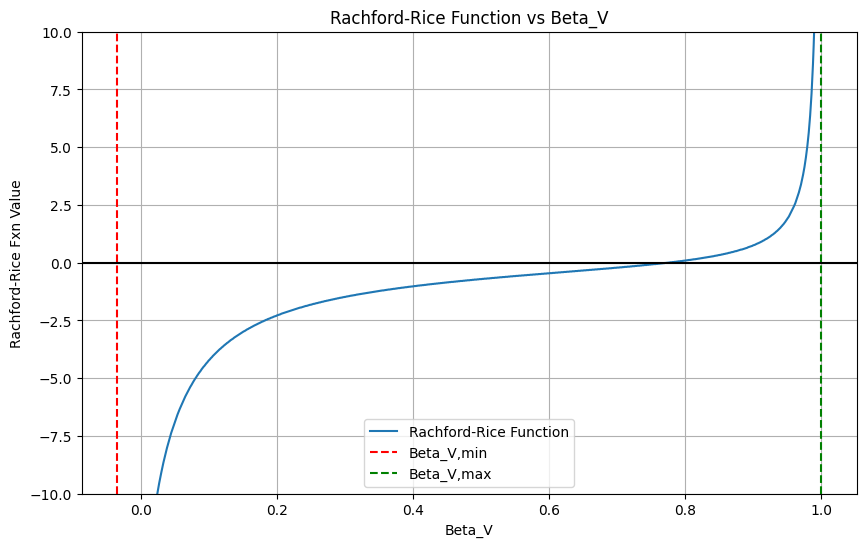

In [673]:
plot_RR_function(np.array([0.61, 0.28, 0.11]), np.array([29.7, 0.45, 0.00]))